# Lab 1 — Getting Started with Keras

### Include a Markdown cell below this with your name


Martin Lam

### Google Colab Button section

#### Double click this to see the code for the button

You will be required to make your Google Colab button here. Please see how to do this on Canvas.  
Below is an example. It will not go anywhere because _username_, _repo_ and _path-to-file_ need to be updated.  
username is your github username.  
repo is the name of your repo.  
path-to-file is the path to the file. So if this was the (username) BS-CS (repo) CSB410_Labs repo, it would be Labs/week02_lab.ipynb.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MartinLam12/csb-410/blob/main/Lab1/lab1.ipynb)


## A.1 Colab / Environment Check


In [3]:
import sys, numpy as np, tensorflow as tf
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Python: 3.12.15
NumPy: 2.5.4
TensorFlow: 2.21.0


## A.2 Load and Inspect MNIST


Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


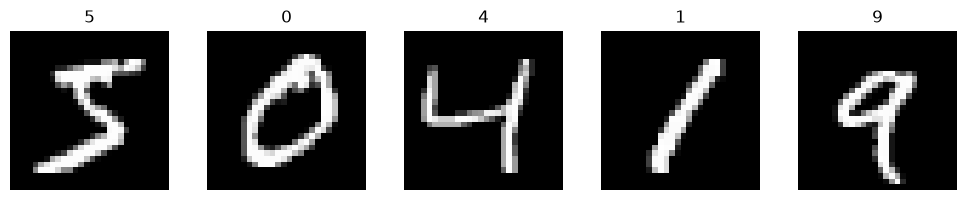

In [4]:
# TODO: load MNIST via keras.datasets and assign to x_train, y_train, x_test, y_test
from tensorflow import keras
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# TODO: print shapes
print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)

# TODO: visualize first 5 samples using matplotlib (grayscale)
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(int(y_train[i]))
    plt.axis("off")
plt.tight_layout()

## A.3 Preprocess Data


In [5]:
# TODO: normalize images to [0,1] and flatten to length 784
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
x_train = x_train.reshape((x_train.shape[0], 784))
x_test  = x_test.reshape((x_test.shape[0], 784))
num_classes = 10

# Sanity checks (do not modify)
assert x_train.shape[1] == 784 and x_test.shape[1] == 784, "Flattening incorrect"
print("Flattened:", x_train.shape, x_test.shape)

Flattened: (60000, 784) (10000, 784)


## A.4 Build a Shallow Network


In [6]:
# TODO: build Sequential model: The Input will be 784.
# The first layer will be Dense of 128 neurons and use the ReLU activation function
# The second layer willbe Dense of 10 neurons and use the Softmax activation function
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## A.5 Compile and Train


In [7]:
# TODO: compile with Adam(1e-3). The loss will be Sparse Categorical Cross Entropy
# Compile with the metric of Accuracy
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# TODO: train for 5 epochs with validation split of 10% and batch size of 128
history = model.fit(x_train, y_train, validation_split=0.1, epochs=5, batch_size=128, verbose=2)

Epoch 1/5
422/422 - 1s - 1ms/step - accuracy: 0.8959 - loss: 0.3746 - val_accuracy: 0.9572 - val_loss: 0.1685
Epoch 2/5
422/422 - 0s - 981us/step - accuracy: 0.9500 - loss: 0.1736 - val_accuracy: 0.9682 - val_loss: 0.1253
Epoch 3/5
422/422 - 0s - 824us/step - accuracy: 0.9634 - loss: 0.1276 - val_accuracy: 0.9697 - val_loss: 0.1059
Epoch 4/5
422/422 - 0s - 898us/step - accuracy: 0.9711 - loss: 0.0997 - val_accuracy: 0.9715 - val_loss: 0.0984
Epoch 5/5
422/422 - 0s - 800us/step - accuracy: 0.9763 - loss: 0.0811 - val_accuracy: 0.9745 - val_loss: 0.0898


## A.6 Evaluate, Predict, Visualize


Test accuracy: 0.9699 | Test loss: 0.0954


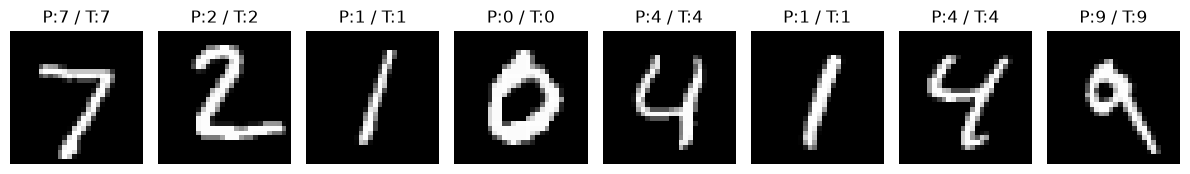

In [8]:
# TODO: evaluate on test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

# TODO: predict and convert to labels with argmax
import numpy as np, matplotlib.pyplot as plt
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# TODO: show 8 images with predicted vs true labels
# Result should be Test accuracy: 0.9431 | Test loss: 0.1969 or something close
# and then pictures of numbers in the MNIST dataset
fig = plt.figure(figsize=(12,3))
for i in range(8):
    plt.subplot(1,8,i+1)
    plt.imshow(x_test.reshape(-1,28,28)[i], cmap="gray")   # x_test
    plt.title(f"P:{int(y_pred[i])} / T:{int(y_test[i])}")  # y_test
    plt.axis("off")
plt.tight_layout()

## A.7 Answer the following discussion questions in Markdown. Please ensure your answers are robust, being composted of a minimum of 3 sentences each.

1. Why is it important to normalize image pixel values to the range [0, 1] before training a neural network, and what might happen to model performance if normalization is skipped?
2. In the Week 2 model, we used a single hidden layer with 128 units and a ReLU activation. How might increasing or decreasing the number of units in this layer affect training speed, overfitting risk, and model accuracy?


**1**

Raw pixel values run from 0 to 255, which are big numbers compared to the small weights a neural network starts with. Scaling them down to 0–1 keeps the numbers small and on the same scale, so the network can learn. If we skip normalization, the large inputs can make the loss jump around and the gradients get too big, so training becomes slow or unstable. The model could end up with lower accuracy.

**2**

More units give the model more capacity to learn patterns, so training accuracy usually goes up. But it also means more weights to compute, so each epoch takes longer, and the model is more likely to overfit by memorizing the training data instead of learning general patterns. Fewer units train faster and overfit less, but the model may be too simple to capture the patterns, so accuracy can drop